In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.signal as signal
import scipy.ndimage as nd
from PIL import Image

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
imgpath = '/content/drive/MyDrive/의료영상처리/DIP4E'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. object counting에 사용할 image를 grayscale로 불러오기

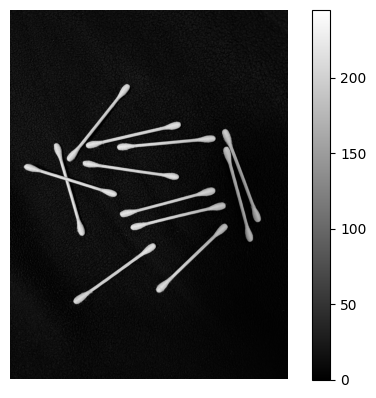

In [ ]:
I = Image.open(imgpath+'/IMG_9627.jpg').convert('L')
f = np.array(I)
plt.imshow(f,cmap='gray')
plt.axis('off')
plt.colorbar()
plt.show()

## 2. 적절한 전처리를 통해 영상의 noise를 줄이기

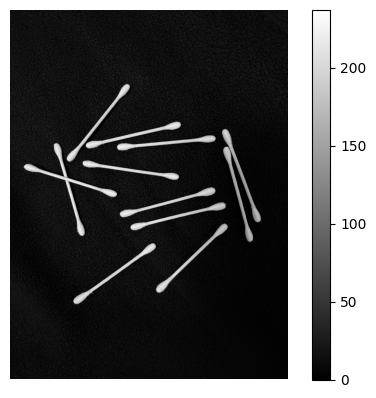

In [ ]:
f_denoised = signal.medfilt2d(f,7)
plt.imshow(f_denoised,cmap='gray')
plt.axis('off')
plt.colorbar()
plt.show()

## 3. 적절한 임계값을 찾아 thresholding을 통해 binary mask를 생성하기

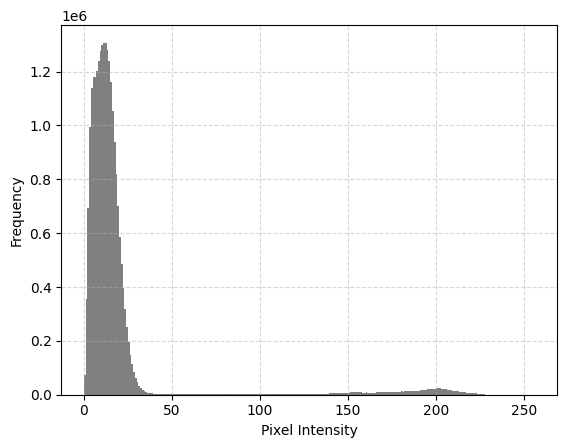

In [ ]:
plt.hist(f_denoised.ravel(), bins=256, range=(0,256), color='gray')
plt.xlabel('Pixel Intensity')
plt.ylabel('Frequency')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

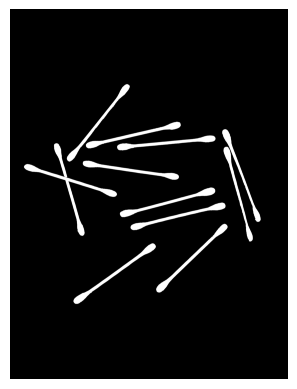

In [ ]:
th_val = 128
f_mask = f_denoised > th_val
plt.imshow(f_mask,cmap='gray')
plt.axis('off')
plt.show()

## 4. Connected component 추출을 통해 object를 분리하고, 각각의 pixel수를 계산하기

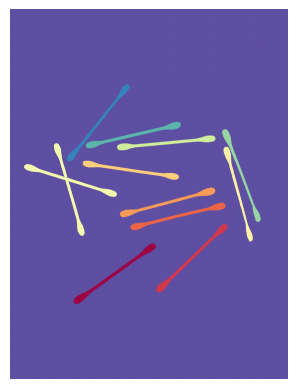

In [ ]:
labels, nums = nd.label(f_mask)
plt.imshow(labels,cmap='Spectral_r')
plt.axis('off')
plt.show()

In [ ]:
cc = np.zeros((nums,2))
for i in range(1,nums+1):
  cc[i-1,0] = i
  cc[i-1,1] = np.sum(labels==i)
  print(f'index: {int(cc[i-1,0])}, number of pixels: {int(cc[i-1,1])}')

index: 1, number of pixels: 84396
index: 2, number of pixels: 90587
index: 3, number of pixels: 79622
index: 4, number of pixels: 91127
index: 5, number of pixels: 166819
index: 6, number of pixels: 75712
index: 7, number of pixels: 86434
index: 8, number of pixels: 91394
index: 9, number of pixels: 88680
index: 10, number of pixels: 90183
index: 11, number of pixels: 94138


## 5. 추출한 connected component 중 가장 큰 것과 작은 것을 시각화하기

In [ ]:
ind_max = np.argmax(cc[:,1])
print(f'the largest component: index {int(cc[ind_max,0])}, # of pixels: {int(cc[ind_max,1])}')

ind_min = np.argmin(cc[:,1])
print(f'the smallest component: index {int(cc[ind_min,0])}, # of pixels: {int(cc[ind_min,1])}')

the largest component: index 5, # of pixels: 166819
the smallest component: index 6, # of pixels: 75712


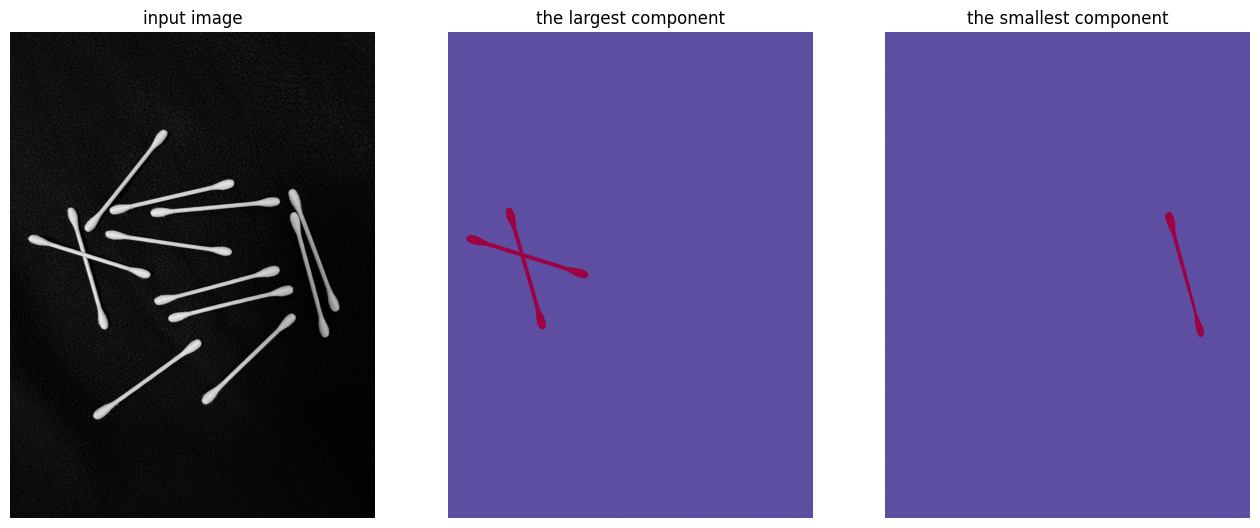

In [ ]:
plt.figure(figsize=(16,9))
plt.subplot(131)
plt.imshow(f,cmap='gray')
plt.axis('off')
plt.title('input image')
plt.subplot(132)
plt.imshow(labels==cc[ind_max,0],cmap='Spectral_r')
plt.axis('off')
plt.title('the largest component')
plt.subplot(133)
plt.imshow(labels==cc[ind_min,0],cmap='Spectral_r')
plt.axis('off')
plt.title('the smallest component')
plt.show()

Result Analysis

직접 촬영한 12개의 면봉 사진에 7×7 Median Filter와 임계값 128을 적용하여 이진 영상을 생성하였다.

Connected Component Labeling 결과 총 11개의 연결 요소가 검출되었다. 실제 면봉은 12개이지만 일부 면봉을 의도적으로 교차시켰기 때문에 서로 연결된 면봉이 하나의 객체로 검출되었다.

가장 큰 연결 요소는 Label 5(166,819 pixels), 가장 작은 연결 요소는 Label 6(75,712 pixels)이었다.

이를 통해 Connected Component Labeling은 실제 물체의 개수가 아니라 이진 영상에서 픽셀의 연결성을 기준으로 객체를 구분한다는 것을 확인하였다.